# HOTEL — Báo cáo hiểu sâu dữ liệu

**Phạm vi: EDA trên dữ liệu gốc; chưa feature engineering, chưa huấn luyện mô hình.**

Báo cáo có từ điển dữ liệu, kiểm tra chất lượng/khóa/nhãn, thống kê theo nhóm, thời gian và giới hạn suy rộng. Các kết quả được tính lại từ CSV; bản đọc nhanh nằm ở `reports/HOTEL/README.md`.

Mọi phân nhóm tạm thời chỉ phục vụ mô tả, không tạo tập feature. Chạy tất cả các cell theo thứ tự; cell đầu quét dữ liệu đầy đủ nên có thể mất vài phút với Expedia.

In [1]:
from pathlib import Path
import importlib
import sys

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / 'data' / 'raw').is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError('Không tìm thấy data/raw; hãy mở notebook trong dự án Propensity.')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from scripts import build_descriptive_reports as eda
importlib.reload(eda)
report = eda.build_report('HOTEL', PROJECT_ROOT)
print('Đã tính lại từ CSV raw; số chính:', report.facts)
print('Chỉ xuất báo cáo, metadata và biểu đồ; không tạo dữ liệu mô hình.')

Đã tính lại từ CSV raw; số chính: {'rows': 119390, 'columns': 32, 'positive': 44224, 'rate': 0.37041628277075134, 'duplicates': 31994, 'deduplicated_rows': 87396, 'deduplicated_rate': 0.27489816467572886}
Chỉ xuất báo cáo, metadata và biểu đồ; không tạo dữ liệu mô hình.


## 1. Bối cảnh, quần thể và câu hỏi phân tích

In [2]:
eda.show_section(report, 'scope')

Dữ liệu hiện có gồm **119,390 booking, 32 cột**, từ City Hotel và Resort Hotel. Mỗi dòng là một booking, không phải một khách hàng duy nhất. Không có booking ID hoặc customer ID để xác nhận danh tính, lịch sử khách hoặc nguyên nhân các dòng trùng.

**Bài toán phù hợp:** xác suất một booking có kết quả hủy/no-show. Không đồng nhất việc hủy một booking với customer churn. Mốc dự đoán (lúc tạo booking hay trước ngày đến) và tập booking còn có thể can thiệp chưa được xác lập; báo cáo chỉ đánh giá tính phù hợp dữ liệu, không ước lượng xác suất bằng mô hình.

Các câu hỏi EDA: nhãn thực sự gồm hành vi nào; khác biệt giữa hai khách sạn; mối liên hệ giữa nhãn và kênh/lead time; tác động của trùng lặp; độ phủ thời gian; biến nào tiết lộ kết quả hoặc chưa chứng minh có sẵn tại thời điểm dự đoán.

Nguồn nghiệp vụ: [Antonio, de Almeida & Nunes — Hotel booking demand datasets](https://pmc.ncbi.nlm.nih.gov/articles/PMC6297060/). Nguồn mô tả hai khách sạn tại Bồ Đào Nha và mốc trích xuất gắn với ngày trước ngày đến. Bản CSV trong dự án có thêm cột `hotel` để phân biệt hai cơ sở. Không suy rộng trực tiếp sang toàn ngành hoặc thị trường Việt Nam.

**Danh mục file gốc; data_lines đếm dòng sau header, đối chiếu số dòng pandas**

,file,data_lines,columns,bytes,sha256
0,hotel_bookings.csv,119390,32,16855599,7c2ae42a7353905ea136e5c2287f17c92c5435826598bf...


## 2. Từ điển dữ liệu và kiểu dữ liệu thực tế

In [3]:
eda.show_section(report, 'dictionary')

Kiểu pandas không đồng nghĩa vai trò thống kê. `agent` và `company` được đọc như số nhưng là ID phân loại. Các cột lịch không phải các phép đo liên tục độc lập. Bảng dưới kiểm kê đủ 32 cột trên toàn bộ dữ liệu.

**Schema, độ đa dạng và missing**

,column,pandas_dtype,distinct_nonnull,missing_n,missing_pct,meaning,role_or_caution
0,hotel,object,2,0,0.0000,City Hotel / Resort Hotel,"Phân khúc; chỉ hai cơ sở gốc, không đại diện t..."
1,is_canceled,int64,2,0,0.0000,"Nhãn kết quả booking, 0/1",Target; dữ liệu hiện tại gộp Canceled và No-Sh...
2,lead_time,int64,479,0,0.0000,Số ngày từ lúc nhập booking đến ngày đến,Kiểm tra mốc dự đoán và lịch sử thay đổi ngày đến
3,arrival_date_year,int64,3,0,0.0000,Năm đến dự kiến,Thời gian; không coi là đại lượng liên tục thô...
4,arrival_date_month,object,12,0,0.0000,Tháng đến dự kiến,Thời gian dạng tên tháng
5,arrival_date_week_number,int64,53,0,0.0000,Tuần của ngày đến,"Thời gian, chồng lặp thông tin với ngày/tháng"
6,arrival_date_day_of_month,int64,31,0,0.0000,Ngày trong tháng của ngày đến,Thời gian
7,stays_in_weekend_nights,int64,17,0,0.0000,Số đêm cuối tuần đặt/lưu trú,Số đếm; xác minh snapshot
8,stays_in_week_nights,int64,35,0,0.0000,Số đêm ngày thường đặt/lưu trú,Số đếm; xác minh snapshot
9,adults,int64,14,0,0.0000,Số người lớn,Kiểm tra 0 và số lượng lớn


## 3. Chất lượng dữ liệu và định nghĩa nhãn

In [4]:
eda.show_section(report, 'quality')

`is_canceled=1` có **44,224 booking (37.04%)**. Bảng chéo xác nhận nhãn này gồm cả `Canceled` và `No-Show`; nhãn 0 là `Check-Out`. Vì vậy tên mục tiêu trong báo cáo là **hủy/no-show**, thay vì chỉ hủy chủ động.

`reservation_status` tiết lộ hoàn toàn nhãn. `reservation_status_date` là ngày trạng thái cuối, cũng thuộc thông tin kết quả. Hai cột chỉ được dùng để hiểu dữ liệu.

`company`/`agent` có nhiều NULL; theo nghiên cứu gốc, NULL ở các cột này có thể nghĩa **không áp dụng**. Không coi các ID này là số liên tục hay mặc định thay NULL bằng trung vị. Với `children`/`country`, nguyên nhân thiếu chưa được xác minh từ CSV.

Nếu giả định loại tất cả dòng trùng, tỷ lệ nhãn 1 đổi từ **37.04%** thành **27.49%**. Đây là độ nhạy đáng kể, không phải chỉ định phải deduplicate. Không có khóa booking nên chưa phân biệt được lỗi lặp với các booking thật có cùng thuộc tính. Các dòng gốc vẫn được giữ nguyên.

ADR âm/cao hoặc booking 0 đêm/0 khách là trường hợp cần xác minh. CSV không chứng minh nguyên nhân là hoàn tiền, voucher hay nhập sai; không clipping hay xóa trong báo cáo.

**Kiểm tra bất thường (các điều kiện có thể chồng lặp)**

,check,n,pct_all_bookings
0,Dòng trùng hoàn toàn; giữ lần xuất hiện đầu để...,31994,26.7979
1,Tổng số khách bằng 0 sau quy ước missing child...,180,0.1508
2,Tổng số đêm bằng 0,715,0.5989
3,ADR âm,1,0.0008
4,ADR bằng 0,1959,1.6408
5,"ADR > 1.000 (ngưỡng kiểm tra, không phải kết l...",1,0.0008
6,Ngày đến không parse được,0,0.0000
7,"Nhãn ngoài {0,1} hoặc thiếu",0,0.0000


**Trạng thái cuối × nhãn**

is_canceled,reservation_status,0,1
0,Canceled,0,43017
1,Check-Out,75166,0
2,No-Show,0,1207


**Độ nhạy theo giả định về duplicate**

,scenario,n,positive,positive_pct
0,Raw: giữ nguyên,119390,44224,37.0416
1,Giả định bỏ mọi dòng trùng (chỉ phân tích độ n...,87396,24025,27.4898


## 4. Phân phối đơn biến và mức độ bao phủ

Thống kê định lượng dùng toàn bộ dữ liệu, bỏ NA riêng ở từng cột. p1/p95/p99 cho thấy phần đuôi mà mean/median có thể che khuất. Bảng category hiển thị top 8 mỗi biến, tỷ lệ luôn chia cho toàn bộ booking (kể cả missing), nên tổng top 8 có thể nhỏ hơn 100%. ADR trên biểu đồ chỉ giới hạn vùng nhìn; dữ liệu và thống kê không bị cắt.

**Thống kê định lượng toàn bộ**

,column,count,mean,std,min,1%,25%,50%,75%,95%,99%,max,missing_pct,skewness
0,lead_time,"119,390.0000",104.0114,106.8631,0.0000,0.0000,18.0000,69.0000,160.0000,320.0000,444.0000,737.0000,0.0000,1.3465
1,stays_in_weekend_nights,"119,390.0000",0.9276,0.9986,0.0000,0.0000,0.0000,1.0000,2.0000,2.0000,4.0000,19.0000,0.0000,1.3800
2,stays_in_week_nights,"119,390.0000",2.5003,1.9083,0.0000,0.0000,1.0000,2.0000,3.0000,5.0000,10.0000,50.0000,0.0000,2.8622
3,adults,"119,390.0000",1.8564,0.5793,0.0000,1.0000,2.0000,2.0000,2.0000,3.0000,3.0000,55.0000,0.0000,18.3178
4,children,"119,386.0000",0.1039,0.3986,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,2.0000,10.0000,0.0034,4.1126
5,babies,"119,390.0000",0.0079,0.0974,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,10.0000,0.0000,24.6465
6,previous_cancellations,"119,390.0000",0.0871,0.8443,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,26.0000,0.0000,24.4580
7,previous_bookings_not_canceled,"119,390.0000",0.1371,1.4974,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,3.0000,72.0000,0.0000,23.5398
8,booking_changes,"119,390.0000",0.2211,0.6523,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,3.0000,21.0000,0.0000,6.0003
9,days_in_waiting_list,"119,390.0000",2.3211,17.5947,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,75.0000,391.0000,0.0000,11.9444


**Phân bố phân loại — top 8/cột**

,column,value,n,pct_all_rows
0,hotel,City Hotel,79330,66.4461
1,hotel,Resort Hotel,40060,33.5539
2,market_segment,Online TA,56477,47.3046
3,market_segment,Offline TA/TO,24219,20.2856
4,market_segment,Groups,19811,16.5935
5,market_segment,Direct,12606,10.5587
6,market_segment,Corporate,5295,4.4350
7,market_segment,Complementary,743,0.6223
8,market_segment,Aviation,237,0.1985
9,market_segment,Undefined,2,0.0017


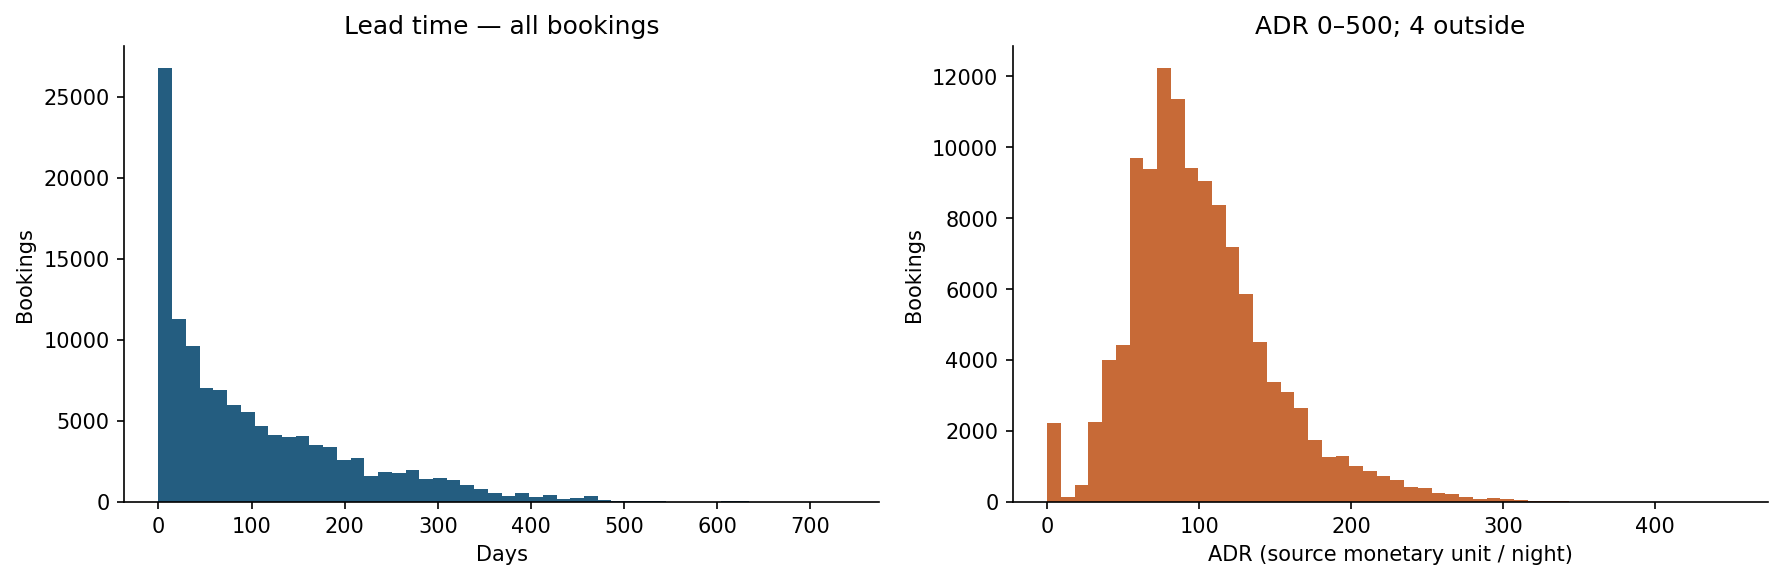

In [5]:
eda.show_section(report, 'distributions')

## 5. Mối liên hệ với nhãn và tương tác phân khúc

Mẫu số là booking trong từng nhóm; không phải tỷ trọng nhóm trong toàn dữ liệu. Các khoảng Wilson 95% là mô tả tham khảo dưới giả định quan sát độc lập; duplicate, booking theo đoàn và khách lặp có thể làm mức bất định thực tế lớn hơn. Nhóm dưới 100 quan sát được gắn cờ, không xếp hạng chắc chắn. Các liên hệ không phải tác động nhân quả của kênh, đặt cọc hoặc thời gian đặt trước. Bảng hotel × market_segment giúp kiểm tra việc khác cơ cấu khách giữa hai cơ sở.

**Tỷ lệ nhãn 1 theo hotel**

,hotel,n,positive,rate_pct,ci95_low_pct,ci95_high_pct,n_under_100
0,City Hotel,79330,33102,41.7270,41.3842,42.0705,False
1,Resort Hotel,40060,11122,27.7634,27.3270,28.2040,False


**Tỷ lệ nhãn 1 theo market_segment**

,market_segment,n,positive,rate_pct,ci95_low_pct,ci95_high_pct,n_under_100
0,Online TA,56477,20739,36.7211,36.3245,37.1196,False
1,Offline TA/TO,24219,8311,34.3160,33.7206,34.9164,False
2,Groups,19811,12097,61.0620,60.3810,61.7388,False
3,Direct,12606,1934,15.3419,14.7233,15.9816,False
4,Corporate,5295,992,18.7347,17.7065,19.8082,False
5,Complementary,743,97,13.0552,10.8215,15.6690,False
6,Aviation,237,52,21.9409,17.1427,27.6342,False
7,Undefined,2,2,100.0000,34.2380,100.0000,True


**Tỷ lệ nhãn 1 theo distribution_channel**

... (9 outputs left out)

**Lead time — nhóm chỉ phục vụ thống kê EDA**

,lead_time_group,n,positive,rate_pct,ci95_low_pct,ci95_high_pct,n_under_100
0,31–90,29553,11141,37.6984,37.1475,38.2525,False
1,91–180,26439,11821,44.7105,44.1120,45.3105,False
2,181–365,21544,11947,55.4540,54.7894,56.1166,False
3,8–30,18960,5283,27.8639,27.2303,28.5065,False
4,1–7,13401,1472,10.9843,10.4660,11.5249,False
5,0,6345,430,6.7770,6.1843,7.4220,False
6,>365,3148,2130,67.6620,66.0073,69.2737,False


**Đối chiếu phân khúc trong từng khách sạn**

,hotel,market_segment,n,positive,positive_pct
0,City Hotel,Aviation,237,52,21.9409
1,City Hotel,Complementary,542,64,11.8081
2,City Hotel,Corporate,2986,641,21.4668
3,City Hotel,Direct,6093,1056,17.3314
4,City Hotel,Groups,13975,9623,68.8587
5,City Hotel,Offline TA/TO,16747,7173,42.8316
6,City Hotel,Online TA,38748,14491,37.3981
7,City Hotel,Undefined,2,2,100.0000
8,Resort Hotel,Complementary,201,33,16.4179
9,Resort Hotel,Corporate,2309,351,15.2014


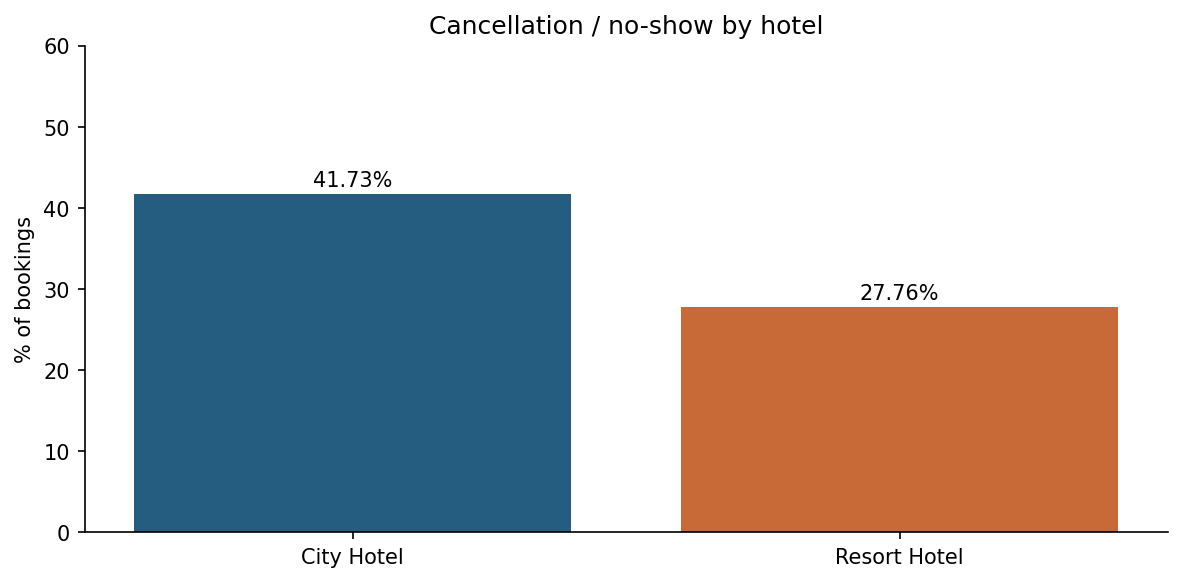

In [6]:
eda.show_section(report, 'target')

## 6. Thời gian, mùa vụ và giới hạn đánh giá

Ngày đến parse được nằm trong **2015-07-01–2017-08-31**. Đây là thời gian ngày đến, không phải thời gian tạo booking. Các tháng đầu/cuối không bao phủ đủ năm, nên không gộp số booking theo tên tháng rồi kết luận mùa vụ. Đồ thị dưới giữ năm–tháng và tách hai khách sạn. Chưa đủ cơ sở để chọn một cách chia tập cuối cùng: cần định nghĩa t0, nhãn đã trưởng thành và đối tượng còn có thể can thiệp; nếu đánh giá tương lai thì ưu tiên giữ trật tự thời gian, đồng thời kiểm tra duplicate qua các tập.

**Toàn bộ năm–tháng × khách sạn**

,year_month,hotel,n,positive,positive_pct
0,2015-07,City Hotel,1398,939,67.1674
1,2015-07,Resort Hotel,1378,320,23.2221
2,2015-08,City Hotel,2480,1232,49.6774
3,2015-08,Resort Hotel,1409,366,25.9759
4,2015-09,City Hotel,3529,1543,43.7234
5,2015-09,Resort Hotel,1585,551,34.7634
6,2015-10,City Hotel,3386,1321,39.0136
7,2015-10,Resort Hotel,1571,411,26.1617
8,2015-11,City Hotel,1235,301,24.3725
9,2015-11,Resort Hotel,1105,185,16.7421


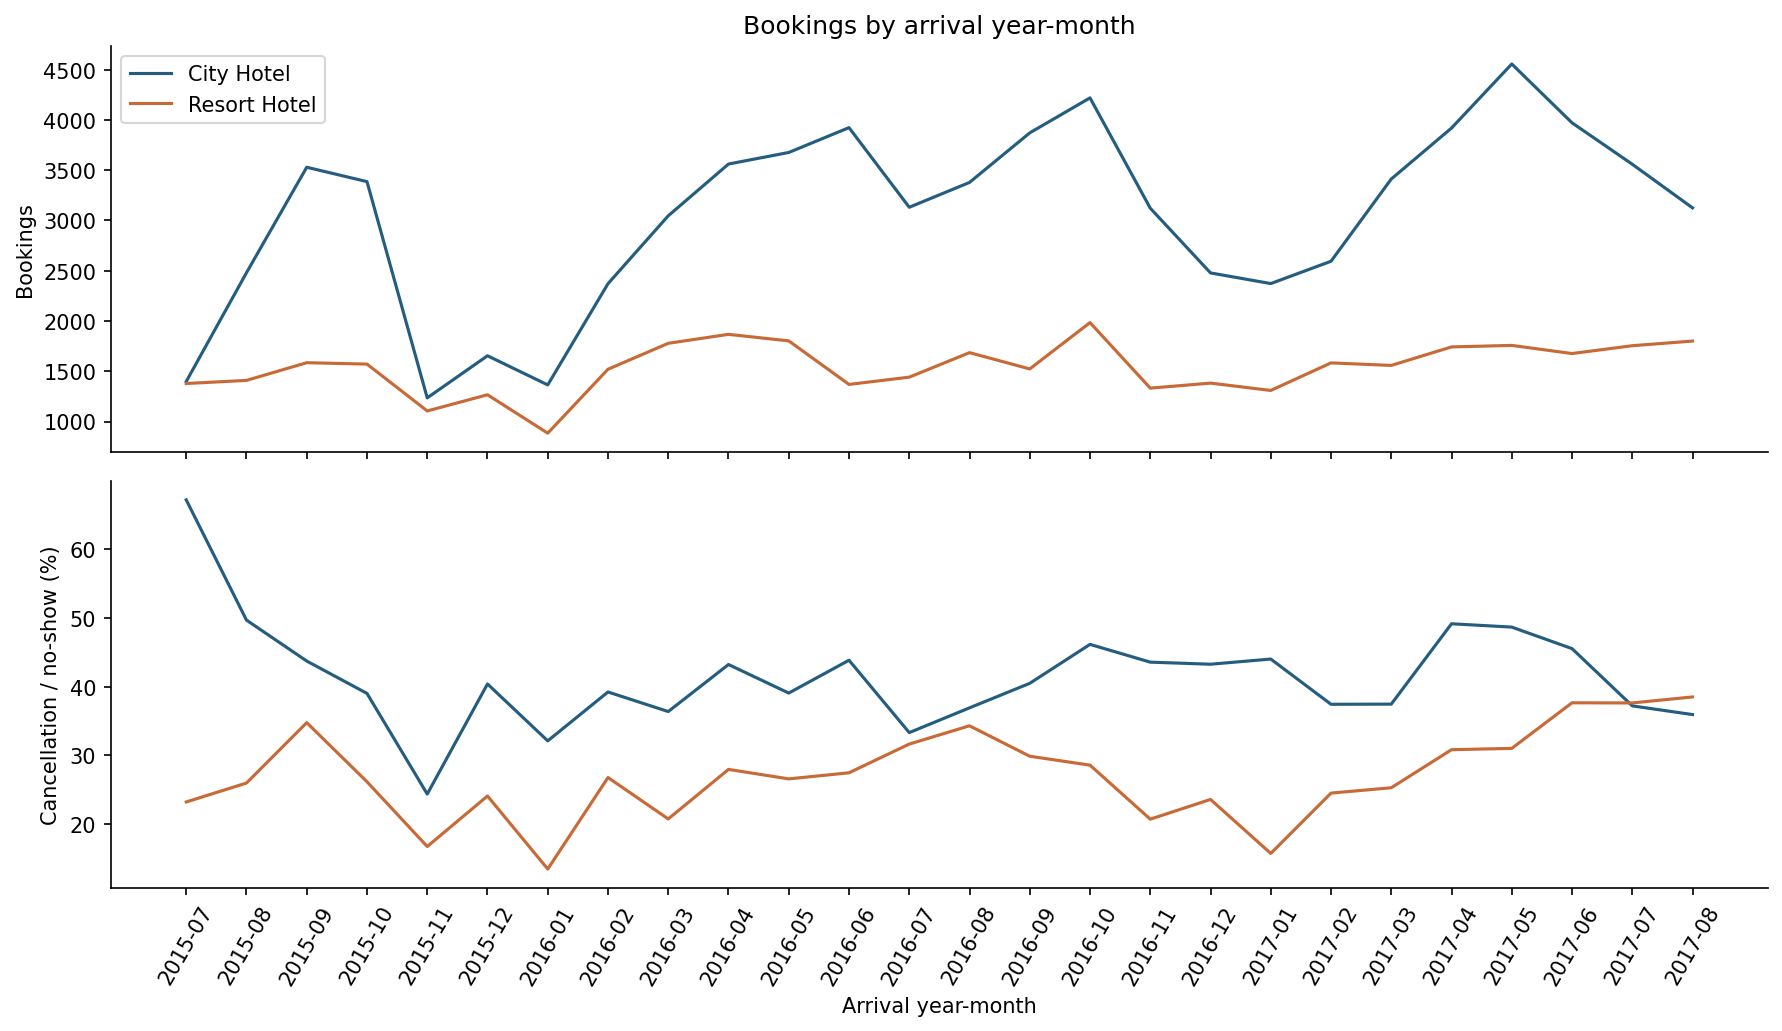

In [7]:
eda.show_section(report, 'time')

## 7. Phụ thuộc giữa các biến

In [8]:
eda.show_section(report, 'dependencies')

Bảng Spearman là tương quan cặp giữa các biến số gốc, dùng các cặp không thiếu. Các phép đo nhiều giá trị 0, category được mã hóa bằng số và dữ liệu lặp có thể làm cách diễn giải khác thường. Không dùng bảng này để tự động loại biến. `market_segment` và `distribution_channel` có thể mô tả chồng lặp; bảng chéo bên dưới kiểm tra cấu trúc thay vì xem hai cột độc lập.

**12 cặp số có |rho| lớn nhất trong danh sách công bố**

,column_a,column_b,spearman_rho
1,lead_time,stays_in_week_nights,0.2963
32,adults,adr,0.2798
38,children,adr,0.2655
10,stays_in_weekend_nights,stays_in_week_nights,0.2381
30,adults,previous_bookings_not_canceled,-0.2096
54,adr,total_of_special_requests,0.1964
2,lead_time,adults,0.1922
6,lead_time,previous_bookings_not_canceled,-0.1886
5,lead_time,previous_cancellations,0.1708
0,lead_time,stays_in_weekend_nights,0.1621


**Market segment × distribution channel**

distribution_channel,market_segment,Corporate,Direct,GDS,TA/TO,Undefined
0,Aviation,227,0,0,10,0
1,Complementary,89,576,0,78,0
2,Corporate,4788,172,0,335,0
3,Direct,90,12276,1,237,2
4,Groups,1228,1472,0,17111,0
5,Offline TA/TO,212,16,45,23946,0
6,Online TA,43,133,147,56153,1
7,Undefined,0,0,0,0,2


## 8. Kết luận và câu hỏi còn mở

In [9]:
eda.show_section(report, 'conclusions')

**Kết luận đã kiểm chứng:** nhãn 1 chiếm 37.04%, gồm hủy và no-show; có 31,994 dòng trùng hoàn toàn; tỷ lệ thay đổi mạnh theo giả định bỏ trùng; hai cơ sở và các kênh có cơ cấu khác nhau. Thông tin trạng thái cuối không thể là đầu vào dự đoán.

**Mức độ phù hợp:** tốt cho nghiên cứu cancellation/no-show ở cấp booking. Chưa đủ để mô tả churn ở cấp khách hàng hoặc mô phỏng chấm điểm ngay lúc tạo booking một cách đáng tin cậy.

**Cần xác minh trước giai đoạn tiếp theo:** (1) thời điểm chấm điểm và tập booking còn hiệu lực; (2) lịch sử giá trị tại t0 cho từng biến, nhất là assigned_room_type, booking_changes, deposit_type, ADR và yêu cầu bổ sung; (3) định danh booking/nhóm để giải thích trùng; (4) ý nghĩa các booking 0 khách/0 đêm và ADR bất thường; (5) phạm vi áp dụng ngoài hai khách sạn.

Không xóa dòng, impute, clipping, encoding, tạo feature hoặc train model trong báo cáo này. Các phân nhóm ngày/tháng và lead time chỉ là bảng thống kê EDA; không được xuất thành tập huấn luyện.

## Tái lập và kiểm soát phạm vi

In [10]:
eda.show_section(report, 'reproducibility')

Chạy notebook theo thứ tự từ đầu, hoặc chạy `python scripts/build_descriptive_reports.py` tại thư mục gốc để dựng lại toàn bộ. Script chỉ đọc CSV raw, viết báo cáo/biểu đồ và lưu notebook trong notebooks/; không sửa raw, không ghi data/processed, không gọi pipeline huấn luyện. Các thời điểm phân tích dùng Asia/Ho_Chi_Minh. SHA-256 ở danh mục file nhận diện nguồn; số dòng theo CSV parser được đối chiếu với data_lines của file chính. Các bảng nhóm chỉ sống trong bộ nhớ để tính EDA. Script thực thi các cell bằng IPython trong cùng tiến trình và lưu output thật vào notebook; không khởi tạo kernel mạng. Phụ thuộc dựng báo cáo gồm pandas, numpy, matplotlib, nbformat và IPython; có thể mở notebook bằng Jupyter để Run All.

**Môi trường thực thi**

,component,value
0,Python,3.14.2
1,pandas,2.3.3
2,numpy,2.4.1
3,matplotlib,3.10.8
4,Phương pháp,"Thống kê mô tả, không mô hình"
5,Chunk CSV lớn,250000
